# How Stable Are Small LLM Reviewers? — Pilot Study

**Question:** If a small open LLM "reviews" an ICLR 2024 paper (title + abstract) using four prompts that ask for the
*same* 1–10 judgement in slightly different words, how often does its score / accept-reject verdict change?
And does it agree with the real human reviewers?

**Kaggle settings (right sidebar → Session options):** Accelerator = **GPU T4 x2** or **P100**, Internet = **On**.
Run cells top to bottom (*Run All* works). Outputs land in `/kaggle/working/` → download them from the **Output** tab.
If the session dies, just *Run All* again — scoring resumes where it stopped.

## 1. Configuration

In [4]:
import os, re, json, random
import numpy as np
import pandas as pd

MODEL_IDS = ["Qwen/Qwen2.5-1.5B-Instruct", "Qwen/Qwen2.5-3B-Instruct"]  # two sizes → "does scale help?"
DATASET_ID = "smallari/openreview-iclr2024-peer-reviews-RAW"           # public mirror of OpenReview ICLR 2024
N_PER_CLASS = 30        # 30 accepted + 30 rejected papers
SEED = 42
ACCEPT_THRESHOLD = 6    # LLM score >= 6 counts as an "accept" verdict (ICLR's 6 = "marginally above threshold")
BATCH_SIZE = 8

OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
os.makedirs(f"{OUT}/data", exist_ok=True)
os.makedirs(f"{OUT}/results", exist_ok=True)
random.seed(SEED)
np.random.seed(SEED)

## 2. Data: 60 ICLR 2024 papers with human ratings

In [5]:
from datasets import load_dataset

raw = load_dataset(DATASET_ID, split="raw").to_pandas()
print(raw.shape)
print(raw["decision"].value_counts())

def human_ratings(reviews):
    """Each review's rating looks like '6: marginally above the acceptance threshold' -> 6."""
    out = []
    for r in (reviews if reviews is not None else []):
        m = re.match(r"\s*(\d+)", r.get("rating") or "")
        if m:
            out.append(int(m.group(1)))
    return out

raw["ratings"] = raw["reviews"].apply(human_ratings)
df = raw[(raw["year"] == "2024")
         & raw["label"].isin([0, 1])
         & raw["abstract"].fillna("").str.strip().astype(bool)
         & (raw["ratings"].str.len() >= 3)].drop_duplicates("paper_id").copy()
df["n_reviews"] = df["ratings"].str.len()
df["human_mean"] = df["ratings"].apply(np.mean)
df["human_std"] = df["ratings"].apply(np.std)   # disagreement between human reviewers

papers = pd.concat([df[df["label"] == lab].sample(N_PER_CLASS, random_state=SEED) for lab in (1, 0)])
papers = papers[["paper_id", "title", "abstract", "decision", "label",
                 "n_reviews", "human_mean", "human_std", "ratings"]].reset_index(drop=True)
papers.to_csv(f"{OUT}/data/papers.csv", index=False)

assert len(papers) == 2 * N_PER_CLASS
print(papers.groupby("label")[["human_mean", "human_std", "n_reviews"]].mean().round(2))

(7404, 8)
decision
Reject                3519
Accept (poster)       1808
Accept (spotlight)     367
Accept (oral)           86
Name: count, dtype: int64
       human_mean  human_std  n_reviews
label                                  
0            4.62       1.00       3.97
1            6.37       0.89       3.93


## 3. Four reviewer prompts
All four ask for the same thing (an overall 1–10 score from title + abstract). They differ only in
**wording**, **layout**, and **where the instruction sits** — features that should not change a good reviewer's score.

In [6]:
PROMPTS = {
    # role-play framing, instruction before content
    "P1_expert": ("You are an expert reviewer for ICLR. Read the title and abstract below and rate the paper's "
                  "overall quality on a scale from 1 (strong reject) to 10 (strong accept). "
                  "Respond with a single integer only.\n\nTitle: {title}\n\nAbstract: {abstract}"),
    # plain task description, no role
    "P2_plain": ("Below is a submission to the ICLR conference. As a reviewer, score it from 1 to 10, where 10 means "
                 "a clear accept and 1 means a clear reject. Output just the number.\n\n"
                 "Title: {title}\nAbstract: {abstract}"),
    # same content, instruction AFTER the paper
    "P3_after": ("Title: {title}\n\nAbstract: {abstract}\n\nYou are reviewing this paper for ICLR, a top machine "
                 "learning conference. On a 1-10 scale (1 = strong reject, 10 = strong accept), what score would you "
                 "give? Reply with one integer and nothing else."),
    # terse, markdown-structured format
    "P4_terse": ("Rate this ICLR submission.\nScale: 1 (definitely reject) to 10 (definitely accept).\n"
                 "Format: a single integer.\n\n### Title\n{title}\n\n### Abstract\n{abstract}"),
}

## 4. Score every paper × prompt × model (greedy decoding = deterministic)

In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

SCORES_CSV = f"{OUT}/results/scores.csv"

def parse_score(text):
    """First integer 1-10 in the model's reply, else NaN."""
    m = re.search(r"\b(10|[1-9])\b", text)
    return int(m.group(1)) if m else np.nan

done = pd.read_csv(SCORES_CSV) if os.path.exists(SCORES_CSV) else pd.DataFrame(columns=["model", "paper_id", "prompt_id"])
done_keys = set(zip(done["model"], done["paper_id"], done["prompt_id"]))

for model_id in MODEL_IDS:
    jobs = [(p.paper_id, pid, tmpl.format(title=p.title.strip(), abstract=p.abstract.strip()))
            for p in papers.itertuples() for pid, tmpl in PROMPTS.items()
            if (model_id, p.paper_id, pid) not in done_keys]
    if not jobs:
        print("already done:", model_id)
        continue
    tok = AutoTokenizer.from_pretrained(model_id, padding_side="left")
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16, device_map="auto").eval()
    for i in range(0, len(jobs), BATCH_SIZE):
        batch = jobs[i:i + BATCH_SIZE]
        texts = [tok.apply_chat_template([{"role": "user", "content": c}], tokenize=False, add_generation_prompt=True)
                 for _, _, c in batch]
        enc = tok(texts, return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=8, do_sample=False, temperature=None, top_p=None, top_k=None,
                                 pad_token_id=tok.pad_token_id)
        outs = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        rows = [{"model": model_id, "paper_id": pid, "prompt_id": pr, "raw_output": o.strip(), "score": parse_score(o)}
                for (pid, pr, _), o in zip(batch, outs)]
        # append after every batch so a crash never loses finished work
        pd.DataFrame(rows).to_csv(SCORES_CSV, mode="a", header=not os.path.exists(SCORES_CSV), index=False)
        print(f"{model_id}: {min(i + BATCH_SIZE, len(jobs))}/{len(jobs)}", end="\r")
    print()
    del model
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-3B-Instruct: 240/240


## 5. Sanity checks — target: ≥95% of outputs parse to a score

In [8]:
scores = pd.read_csv(SCORES_CSV)
print("rows:", len(scores))
print("parse rate by model:\n", scores.groupby("model")["score"].apply(lambda s: s.notna().mean()).round(3))
print(scores.sample(5, random_state=SEED)[["model", "prompt_id", "raw_output", "score"]].to_string())

rows: 480
parse rate by model:
 model
Qwen/Qwen2.5-1.5B-Instruct    1.0
Qwen/Qwen2.5-3B-Instruct      1.0
Name: score, dtype: float64
                          model prompt_id raw_output  score
73   Qwen/Qwen2.5-1.5B-Instruct  P2_plain          8      8
414    Qwen/Qwen2.5-3B-Instruct  P3_after          8      8
394    Qwen/Qwen2.5-3B-Instruct  P3_after          8      8
277    Qwen/Qwen2.5-3B-Instruct  P2_plain          8      8
399    Qwen/Qwen2.5-3B-Instruct  P4_terse          8      8


## 6. Metrics
* **score std across prompts** (per paper, averaged) — how much wording alone moves the score
* **verdict flip rate** — share of papers whose accept/reject verdict differs between at least two prompts
* **Spearman ρ vs human mean rating** and **AUC for accept/reject** — does the model agree with humans at all?
* **prompt-averaged score** — does averaging over prompts help? (seed idea for a later paper)

In [9]:
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

meta = papers.set_index("paper_id")

def wide_scores(model_id):
    s = scores[(scores["model"] == model_id)].dropna(subset=["score"])
    return s.pivot_table(index="paper_id", columns="prompt_id", values="score").dropna()  # papers scored by every prompt

def agreement(x, y):
    return {"spearman_vs_human": spearmanr(x, y["human_mean"])[0],
            "auc_accept": roc_auc_score(y["label"], x) if x.nunique() > 1 else np.nan,
            "accuracy_at_threshold": ((x >= ACCEPT_THRESHOLD) == y["label"].astype(bool)).mean()}

metrics = {}
for model_id in MODEL_IDS:
    wide = wide_scores(model_id)
    y = meta.loc[wide.index]
    verdict = wide >= ACCEPT_THRESHOLD
    metrics[model_id] = {
        "n_papers": len(wide),
        "mean_score_std_across_prompts": wide.std(axis=1, ddof=0).mean(),
        "frac_papers_range_ge_2": ((wide.max(axis=1) - wide.min(axis=1)) >= 2).mean(),
        "verdict_flip_rate": (verdict.nunique(axis=1) > 1).mean(),
        "human_reviewer_std_mean": y["human_std"].mean(),
        "per_prompt": {p: {"mean_score": wide[p].mean(), **agreement(wide[p], y)} for p in wide.columns},
        "prompt_averaged": agreement(wide.mean(axis=1), y),
        "prompt_pair_spearman": wide.corr(method="spearman").round(3).to_dict(),
    }

with open(f"{OUT}/results/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

# one markdown table you can paste straight into the paper / README
lines = ["| Model | Prompt | Mean score | Spearman ρ vs human | AUC (accept) | Acc. @≥6 |", "|---|---|---|---|---|---|"]
for model_id, m in metrics.items():
    for p, v in list(m["per_prompt"].items()) + [("**avg of prompts**", {"mean_score": np.nan, **m["prompt_averaged"]})]:
        lines.append(f"| {model_id.split('/')[-1]} | {p} | {v['mean_score']:.2f} | {v['spearman_vs_human']:.2f} | "
                     f"{v['auc_accept']:.2f} | {v['accuracy_at_threshold']:.2f} |")
lines += ["", "| Model | Papers | Mean score std across prompts | Papers with range ≥2 | Verdict flip rate | Human reviewer std (ref.) |",
          "|---|---|---|---|---|---|"]
for model_id, m in metrics.items():
    lines.append(f"| {model_id.split('/')[-1]} | {m['n_papers']} | {m['mean_score_std_across_prompts']:.2f} | "
                 f"{m['frac_papers_range_ge_2']:.0%} | {m['verdict_flip_rate']:.0%} | {m['human_reviewer_std_mean']:.2f} |")
table = "\n".join(lines)
with open(f"{OUT}/results/table.md", "w") as f:
    f.write(table + "\n")
print(table)

| Model | Prompt | Mean score | Spearman ρ vs human | AUC (accept) | Acc. @≥6 |
|---|---|---|---|---|---|
| Qwen2.5-1.5B-Instruct | P1_expert | 8.47 | 0.03 | 0.56 | 0.50 |
| Qwen2.5-1.5B-Instruct | P2_plain | 8.28 | 0.01 | 0.52 | 0.50 |
| Qwen2.5-1.5B-Instruct | P3_after | 8.08 | -0.17 | 0.45 | 0.50 |
| Qwen2.5-1.5B-Instruct | P4_terse | 8.23 | 0.13 | 0.58 | 0.50 |
| Qwen2.5-1.5B-Instruct | **avg of prompts** | nan | 0.09 | 0.57 | 0.50 |
| Qwen2.5-3B-Instruct | P1_expert | 8.30 | -0.09 | 0.44 | 0.50 |
| Qwen2.5-3B-Instruct | P2_plain | 7.97 | 0.01 | 0.52 | 0.50 |
| Qwen2.5-3B-Instruct | P3_after | 7.78 | 0.06 | 0.53 | 0.50 |
| Qwen2.5-3B-Instruct | P4_terse | 7.98 | 0.17 | 0.52 | 0.50 |
| Qwen2.5-3B-Instruct | **avg of prompts** | nan | -0.08 | 0.46 | 0.50 |

| Model | Papers | Mean score std across prompts | Papers with range ≥2 | Verdict flip rate | Human reviewer std (ref.) |
|---|---|---|---|---|---|
| Qwen2.5-1.5B-Instruct | 60 | 0.22 | 3% | 0% | 0.95 |
| Qwen2.5-3B-Instruct | 60 

## 7. Figures (PNG for README, PDF for Overleaf)

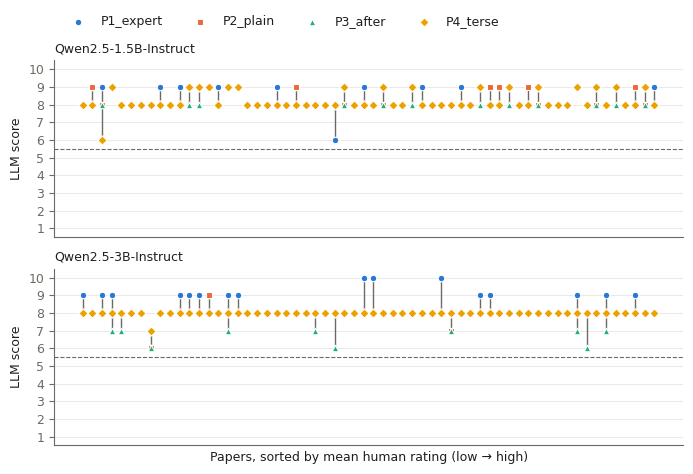

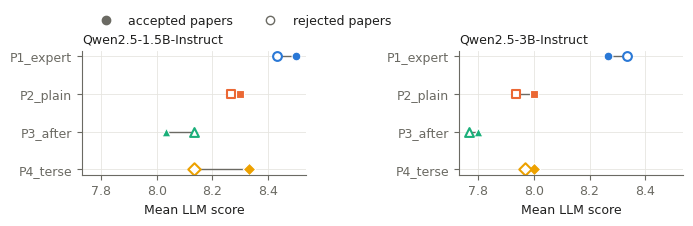

Done. Download data/ and results/ from the Output tab.


In [10]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

COLORS = dict(zip(PROMPTS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))   # colorblind-validated categorical order
MARKERS = dict(zip(PROMPTS, ["o", "s", "^", "D"]))                           # shape = second encoding, never color alone
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5e0"
plt.rcParams.update({"font.size": 9, "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})

def save(fig, name):
    fig.savefig(f"{OUT}/results/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}/results/{name}.pdf", bbox_inches="tight")
    plt.show()

# Figure 1: every paper's four scores, papers sorted by mean human rating
fig, axes = plt.subplots(len(MODEL_IDS), 1, figsize=(7, 2.4 * len(MODEL_IDS)), squeeze=False)
for ax, model_id in zip(axes[:, 0], MODEL_IDS):
    wide = wide_scores(model_id)
    wide = wide.loc[meta.loc[wide.index].sort_values("human_mean").index]
    xs = np.arange(len(wide))
    ax.vlines(xs, wide.min(axis=1), wide.max(axis=1), color=MUTED, linewidth=1, zorder=1)
    for p in wide.columns:
        ax.scatter(xs, wide[p], s=22, marker=MARKERS[p], color=COLORS[p], edgecolor="white", linewidth=0.8,
                   label=p, zorder=2)
    ax.axhline(ACCEPT_THRESHOLD - 0.5, color=MUTED, linestyle="--", linewidth=0.8)
    ax.set_ylim(0.5, 10.5)
    ax.set_yticks(range(1, 11))
    ax.set_xticks([])
    ax.set_ylabel("LLM score")
    ax.set_title(model_id.split("/")[-1], loc="left", fontsize=9)
axes[-1, 0].set_xlabel("Papers, sorted by mean human rating (low → high)")
axes[0, 0].legend(ncol=4, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.12))
fig.tight_layout()
save(fig, "fig1_score_spread")

# Figure 2: mean LLM score for accepted vs rejected papers, per prompt
fig, axes = plt.subplots(1, len(MODEL_IDS), figsize=(3.5 * len(MODEL_IDS), 2.4), sharex=True, squeeze=False)
for ax, model_id in zip(axes[0], MODEL_IDS):
    s = scores[scores["model"] == model_id].dropna(subset=["score"]).merge(papers[["paper_id", "label"]], on="paper_id")
    g = s.groupby(["prompt_id", "label"])["score"].mean().unstack().reindex(list(PROMPTS))
    for yv, (p, row) in enumerate(g.iterrows()):
        ax.plot([row.loc[0], row.loc[1]], [yv, yv], color=MUTED, linewidth=1, zorder=1)
        ax.scatter(row.loc[1], yv, s=40, marker=MARKERS[p], color=COLORS[p], edgecolor="white", linewidth=0.8, zorder=2)
        ax.scatter(row.loc[0], yv, s=40, marker=MARKERS[p], facecolor="white", edgecolor=COLORS[p], linewidth=1.5, zorder=2)
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels(g.index)
    ax.invert_yaxis()
    ax.set_xlabel("Mean LLM score")
    ax.set_title(model_id.split("/")[-1], loc="left", fontsize=9)
handles = [Line2D([], [], marker="o", linestyle="", color=MUTED, label="accepted papers"),
           Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=MUTED, label="rejected papers")]
axes[0, 0].legend(handles=handles, ncol=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.1))
fig.tight_layout()
save(fig, "fig2_accept_vs_reject")

print("Done. Download data/ and results/ from the Output tab.")